# Phase 2 — Member 2: GRU over ordered daily delay sequences

Read-only results summary. Training is done by `scripts/train_gru.py` under the design written
down before training (D-303); this notebook only loads its saved outputs (D-304).

**Question:** do the last L days of delays, read in order by a compact GRU, improve next-day
prediction over the Phase 1 Logistic Regression and the Member 1 MLP, and is any gain due to the
order (recurrence) rather than to the extra inputs?

Protocol (D-301): fit January–July, choose settings and epochs on August, refit January–August,
score September–October once. November–December stays sealed and is never read.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path('..').resolve()
model_dir = ROOT / 'models' / 'phase2' / 'member2'
fig_dir = ROOT / 'reports' / 'figures' / 'phase2_member2'
res_dir = ROOT / 'reports' / 'results' / 'phase2_member2'
config = json.loads((model_dir / 'model_config.json').read_text())
print('Selected sequence length L =', config['selected_length'],
      '| GRU hidden size =', config['selected_hidden_size'],
      '| seeds =', config['seeds'], '| holdout accessed:', config['holdout_accessed'])

Selected sequence length L = 14 | GRU hidden size = 16 | seeds = [42, 43, 44, 45, 46] | holdout accessed: False


## 1. Sequences and architecture

For a flight on day D: the last L days (D−L … D−1, oldest first). A past flight counts on the
day its outcome became known (arrival in New York time + 30 min), so a D−1 flight landing after
23:30 is not in D's sequence. Ten values per day: smoothed delay rate for the whole system,
the flight's origin, carrier and destination; log flight counts for system, origin and carrier;
a carrier has-data flag; weekday (sine/cosine).

The control model gets exactly the same inputs, but flattens the L days instead of reading them
in order with a GRU.

['system_rate', 'system_log_n', 'origin_rate', 'origin_log_n', 'carrier_rate', 'carrier_log_n', 'carrier_has_data', 'dest_rate', 'dow_sin', 'dow_cos']


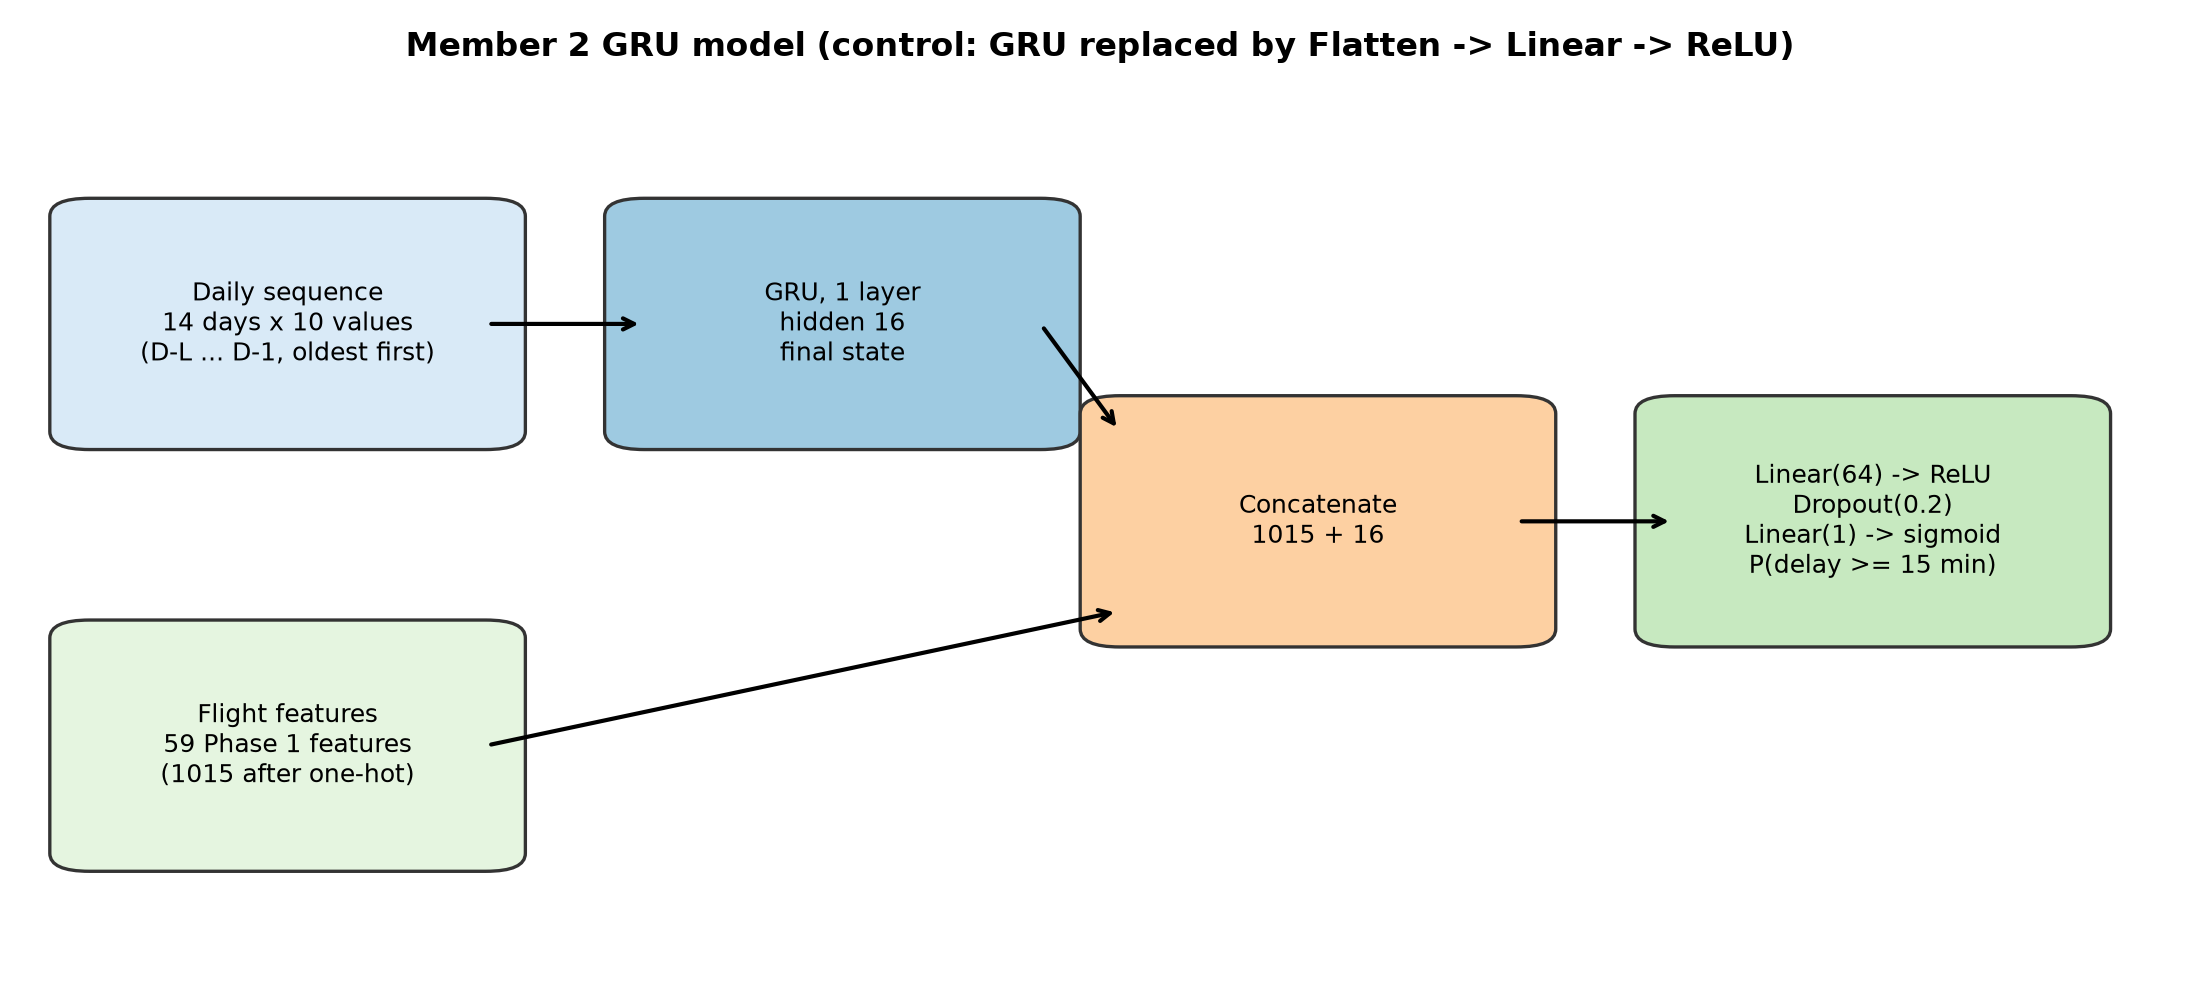

In [2]:
print(config['sequence_channels'])
display(Image(filename=str(fig_dir / 'gru_architecture.png'), width=800))

## 2. Grid on August (GRU, seed 42)

,length,hidden_size,best_epoch,august_pr_auc,august_roc_auc,selected
0,7,16,1,0.3708,0.6568,False
1,7,32,1,0.3692,0.6543,False
2,14,16,2,0.3719,0.6600,True
3,14,32,1,0.3685,0.6538,False
4,28,16,1,0.3715,0.6573,False
5,28,32,1,0.3678,0.6528,False


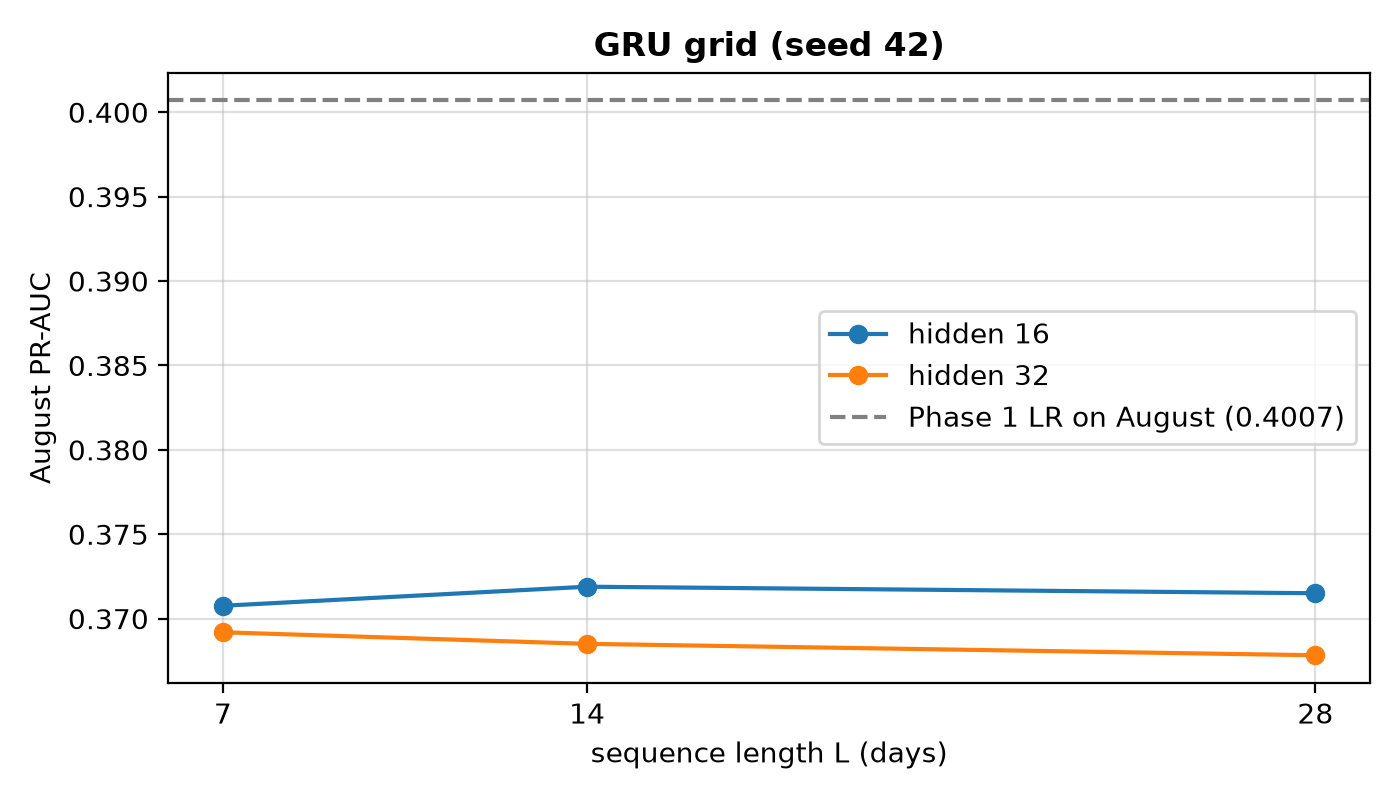

In [3]:
grid = pd.read_csv(res_dir / 'grid_august.csv')
display(grid.round(4))
display(Image(filename=str(fig_dir / 'grid_august_pr_auc.png'), width=550))

## 3. Training curves (selected GRU, seed 42)

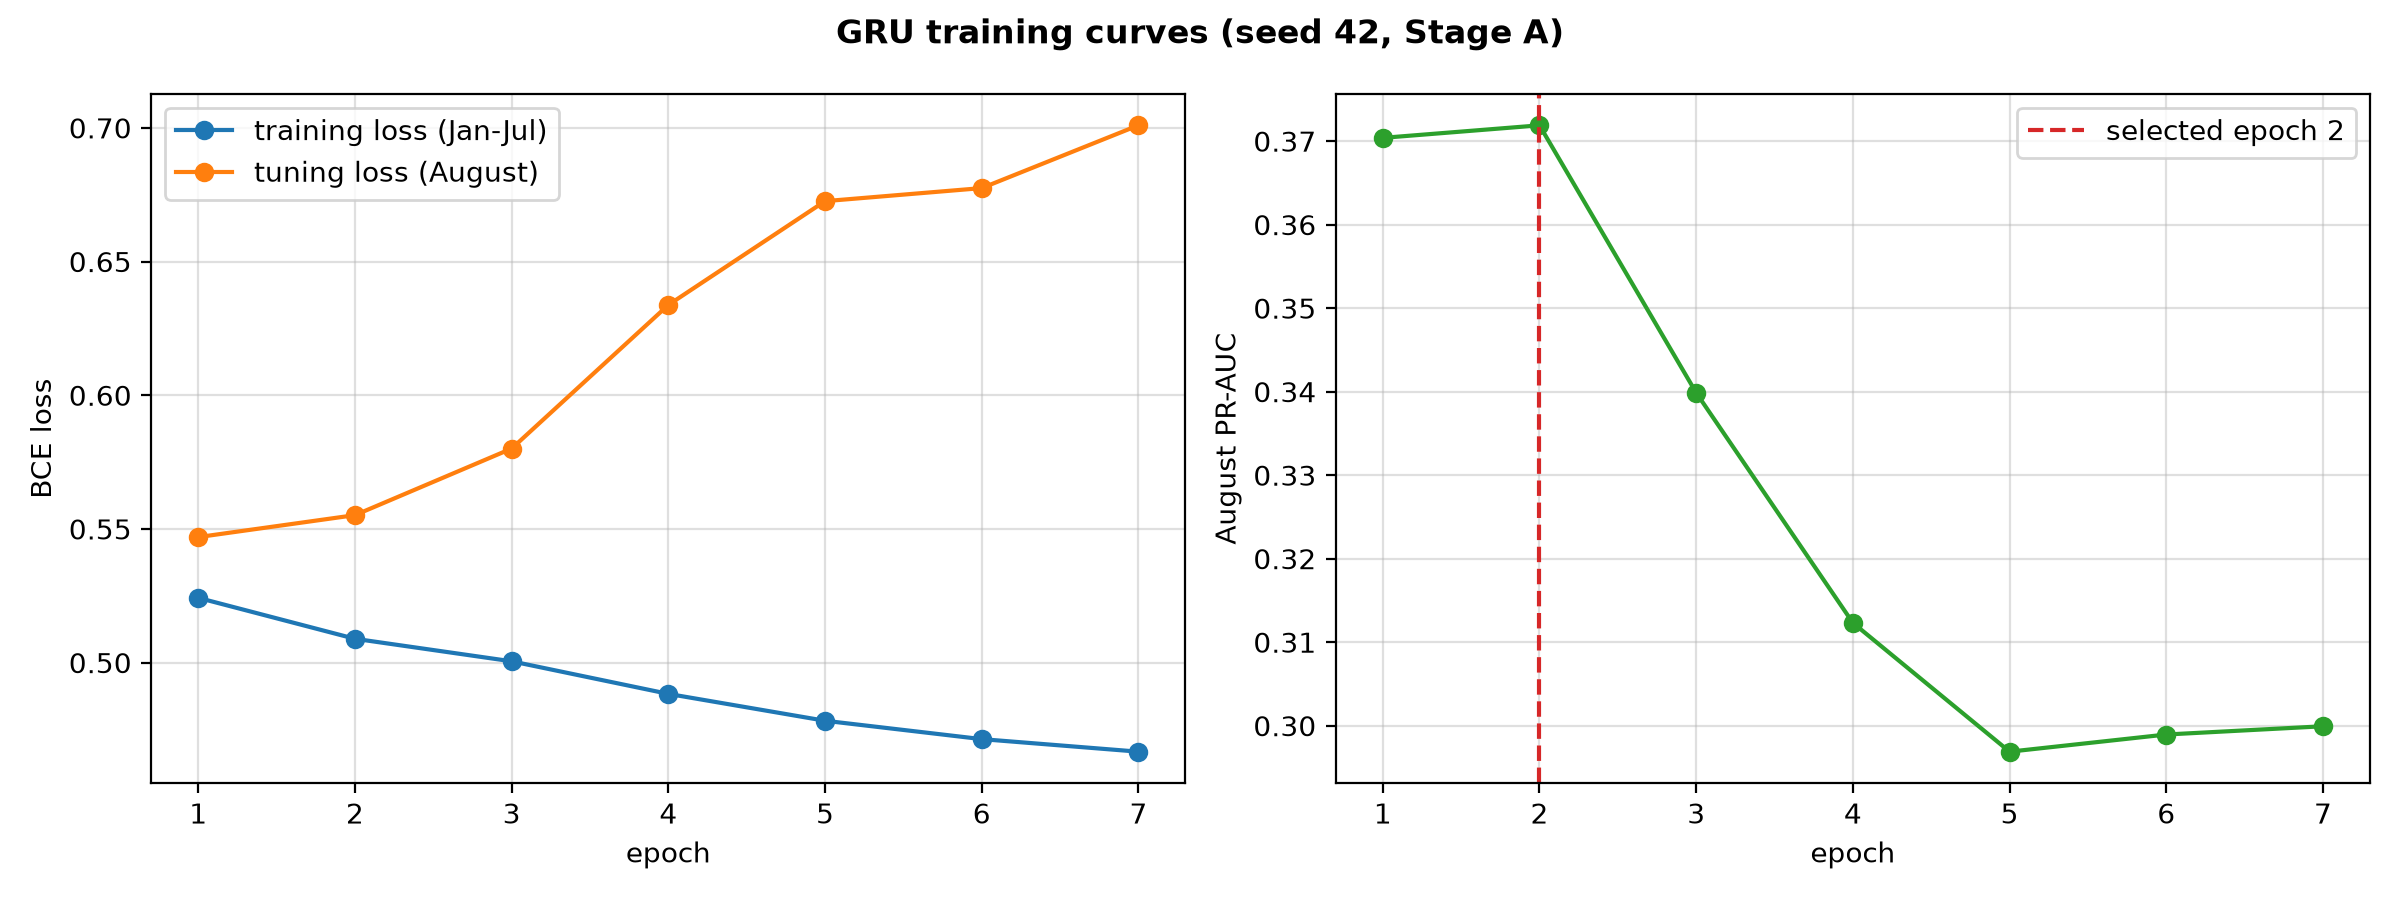

,model,seed,best_epoch,august_pr_auc,august_roc_auc
0,gru,42,2,0.3719,0.6600
1,gru,43,1,0.3707,0.6571
2,gru,44,1,0.3753,0.6567
3,gru,45,1,0.3686,0.6559
4,gru,46,1,0.3644,0.6567
5,control,42,2,0.3697,0.6700
6,control,43,6,0.4437,0.6878
7,control,44,1,0.3839,0.6697
8,control,45,3,0.3993,0.6804
9,control,46,3,0.3895,0.6764


In [4]:
display(Image(filename=str(fig_dir / 'gru_training_curves.png'), width=800))
runs = pd.read_csv(res_dir / 'august_selection_runs.csv')
display(runs.round(4))

## 4. September–October, scored once

Mean and standard deviation over five seeds (the Logistic Regression is a single fixed model).

sep_oct


,label,pr_auc_mean,pr_auc_std,roc_auc_mean,brier_score_mean,ece_10_mean,mean_predicted_probability_mean
4,"GRU (sequence, in order)",0.2946,0.0055,0.6743,0.1360,0.0863,0.2432
10,Logistic Regression (Phase 1),0.2896,NaN,0.6800,0.1855,0.2334,0.3904
7,GRU without the 29 historical features,0.2885,0.0064,0.6748,0.1347,0.0840,0.2410
13,Member 1 MLP (no sequence),0.2839,0.0043,0.6719,0.1333,0.0757,0.2327
1,"Control (same inputs, no recurrence)",0.2553,0.0214,0.6433,0.1458,0.0820,0.2075


september


,label,pr_auc_mean,pr_auc_std,roc_auc_mean,brier_score_mean,ece_10_mean,mean_predicted_probability_mean
11,Logistic Regression (Phase 1),0.2457,NaN,0.6689,0.1790,0.2402,0.3774
8,GRU without the 29 historical features,0.2448,0.0038,0.6686,0.1235,0.0844,0.2216
5,"GRU (sequence, in order)",0.2392,0.0058,0.6618,0.1249,0.0810,0.2182
14,Member 1 MLP (no sequence),0.2177,0.0033,0.6504,0.1251,0.0809,0.2181
2,"Control (same inputs, no recurrence)",0.1980,0.0162,0.6298,0.1338,0.0707,0.1762


october


,label,pr_auc_mean,pr_auc_std,roc_auc_mean,brier_score_mean,ece_10_mean,mean_predicted_probability_mean
12,Member 1 MLP (no sequence),0.3334,0.0054,0.6854,0.1410,0.0730,0.2464
3,"GRU (sequence, in order)",0.3331,0.0094,0.6800,0.1465,0.0926,0.2669
9,Logistic Regression (Phase 1),0.3248,NaN,0.6861,0.1917,0.2270,0.4026
6,GRU without the 29 historical features,0.3197,0.0101,0.6750,0.1453,0.0843,0.2593
0,"Control (same inputs, no recurrence)",0.2975,0.0216,0.6494,0.1570,0.0933,0.2371


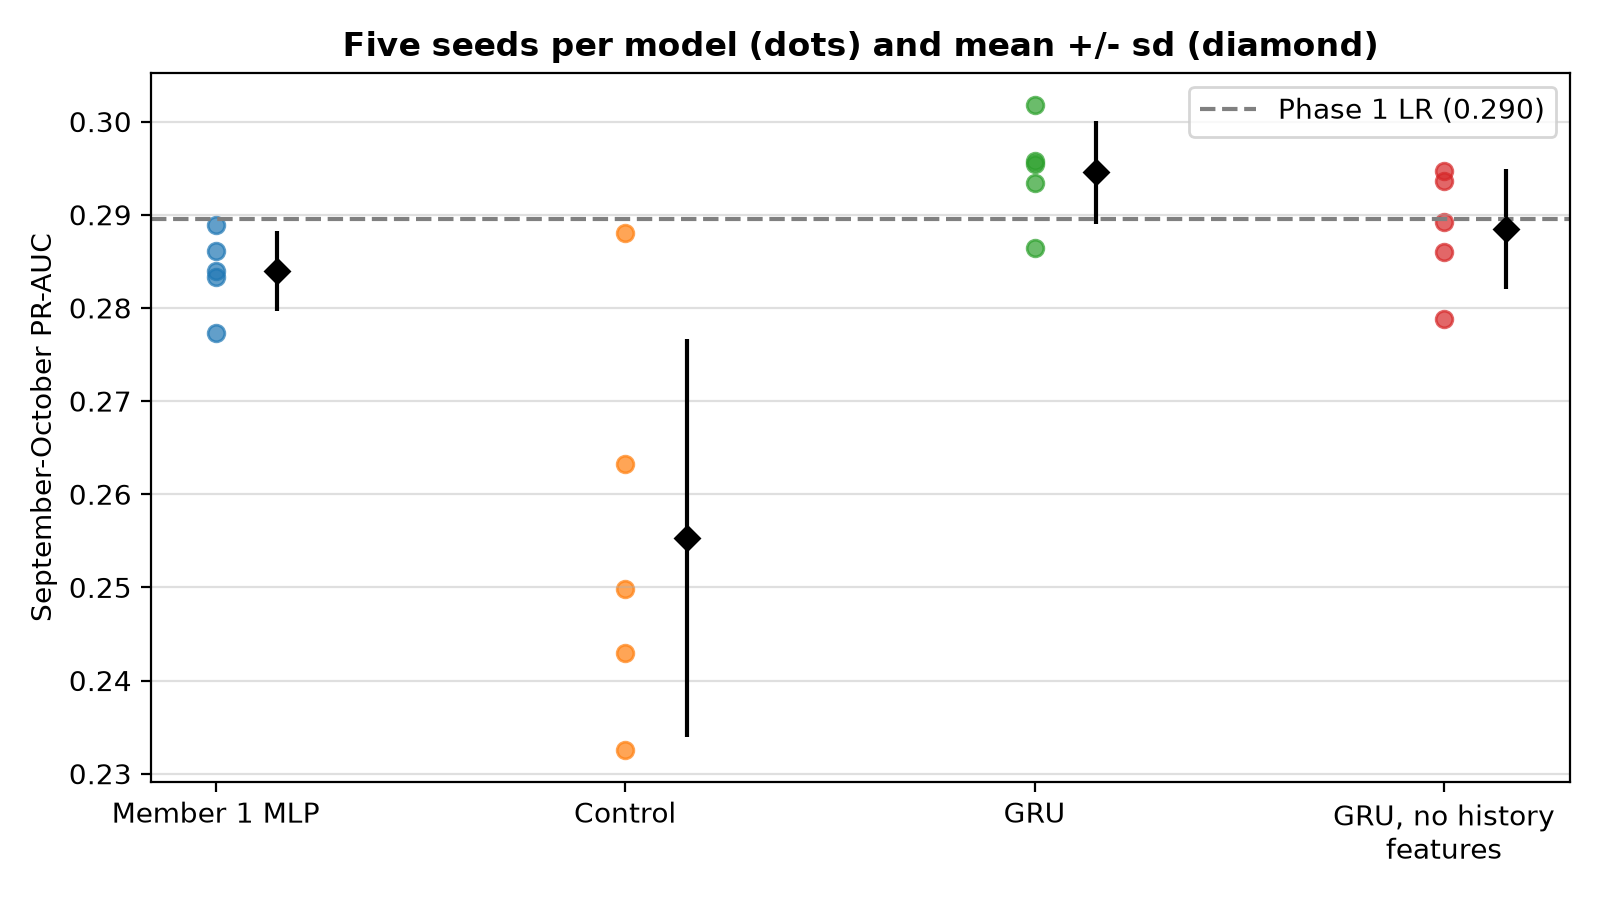

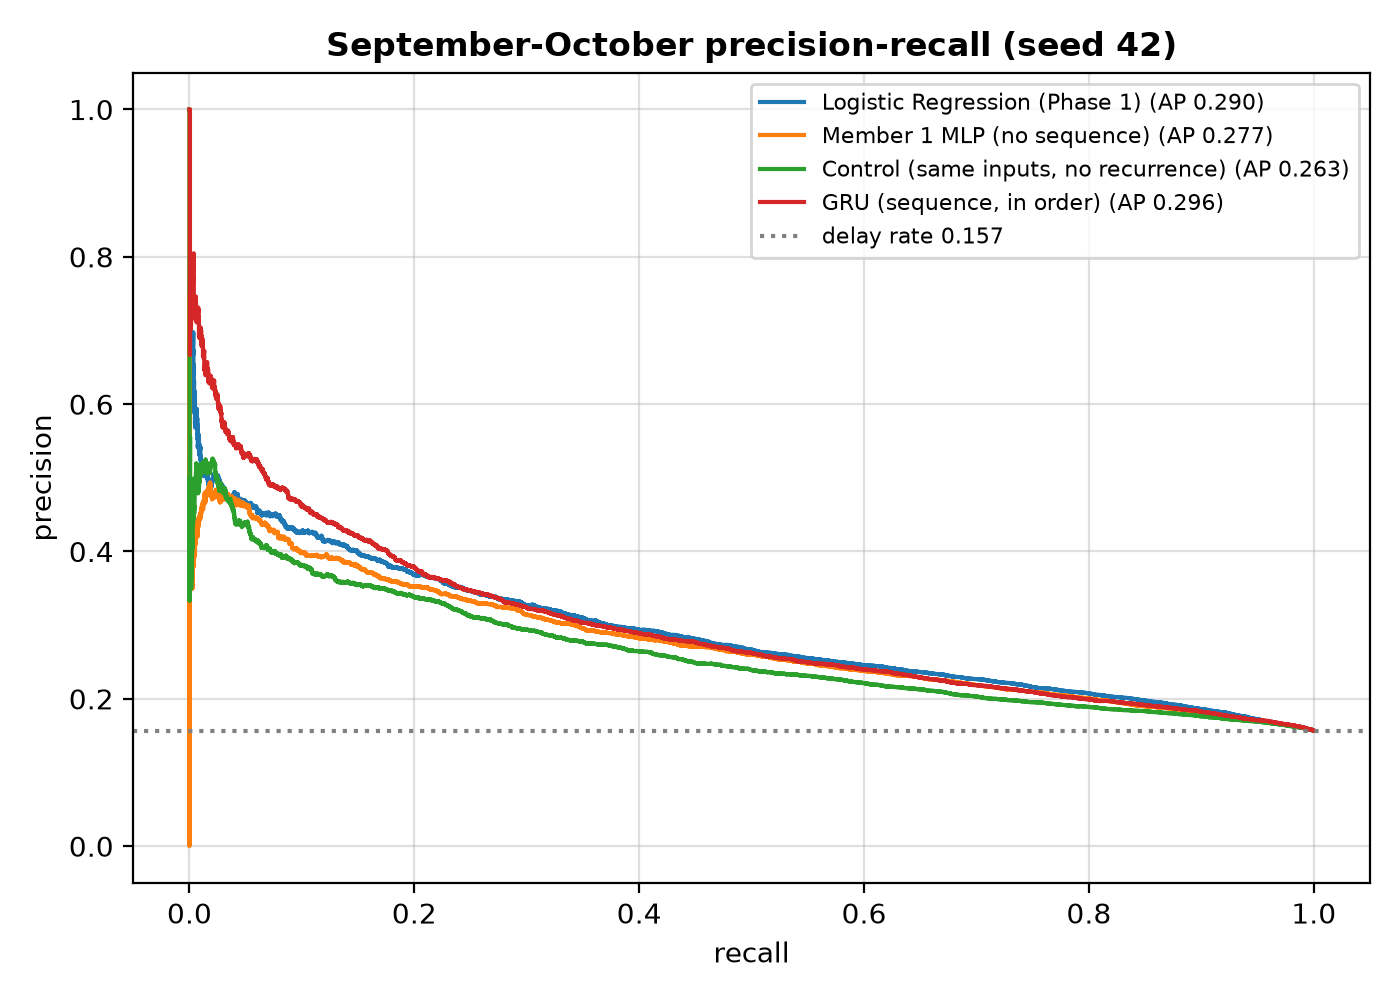

In [5]:
comp = pd.read_csv(res_dir / 'comparison.csv')
cols = ['label', 'pr_auc_mean', 'pr_auc_std', 'roc_auc_mean', 'brier_score_mean', 'ece_10_mean',
        'mean_predicted_probability_mean']
for period in ['sep_oct', 'september', 'october']:
    print(period)
    display(comp.loc[comp['period'] == period, cols].sort_values('pr_auc_mean', ascending=False))
display(Image(filename=str(fig_dir / 'seed_comparison.png'), width=650))
display(Image(filename=str(fig_dir / 'pr_curves_sep_oct.png'), width=550))

## 5. Are the differences real?

95% intervals for PR-AUC differences from a bootstrap that resamples whole days (flights on the
same day share the same weather). A difference counts only if its interval excludes 0 (D-303).

In [6]:
display(pd.read_csv(res_dir / 'bootstrap_pr_auc_differences.csv').round(4))

,comparison,difference,ci_low,ci_high,excludes_zero
0,gru - lr,0.0050,-0.0137,0.0238,False
1,gru - control,0.0393,0.0087,0.0718,True
2,gru - mlp,0.0106,-0.0004,0.0216,False
3,control - lr,-0.0343,-0.0703,0.0058,False
4,mlp - lr,-0.0057,-0.0239,0.0115,False
5,gru_no_history - gru,-0.0061,-0.0220,0.0078,False


## 6. Reading

1. **Recurrence helps compared with the same inputs flattened:** GRU − control = +0.039, 95%
   interval [+0.009, +0.072]. The control is also unstable across seeds.
2. **No model beats the Phase 1 Logistic Regression:** GRU − LR = +0.005 [−0.014, +0.024];
   GRU − MLP = +0.011 [−0.000, +0.022]. The GRU is behind LR in September and ahead in October.
3. **The sequence can replace the hand-made history features:** without the 29 history
   features the GRU loses only 0.006 (not significant).
4. **The limit is the information:** yesterday explains about 12% of today's delay-rate
   variation; the rest is mostly same-day weather, unknown at the end of D−1.

Raw GRU probabilities are too high (0.243 vs 0.157 delay rate); calibration is Member 5's task.